In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

In [6]:
df = pd.read_csv("smart_class_energy_data.csv")

df.head()

,Num_Students,Outdoor_Temp,Time_of_Day,Humidity,Lights_On,Windows_Open,Fan_Speed,AC_Temp
0,33,34.714868,Morning,69.221654,1,0,2,26.911474
1,73,27.689434,Evening,75.267053,1,1,4,22.531882
2,73,38.544262,Afternoon,69.683302,0,0,3,23.523407
3,7,33.203330,Evening,89.243701,1,0,4,22.411541
4,35,33.565462,Evening,68.174341,0,0,1,26.139862


Explore dataset

In [7]:
print(df.shape)

print(df.info())

print(df.describe())

print(df.isnull().sum())

(500, 8)
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Num_Students  500 non-null    int64  
 1   Outdoor_Temp  500 non-null    float64
 2   Time_of_Day   500 non-null    str    
 3   Humidity      500 non-null    float64
 4   Lights_On     500 non-null    int64  
 5   Windows_Open  500 non-null    int64  
 6   Fan_Speed     500 non-null    int64  
 7   AC_Temp       500 non-null    float64
dtypes: float64(3), int64(4), str(1)
memory usage: 31.4 KB
None
       Num_Students  Outdoor_Temp    Humidity   Lights_On  Windows_Open  \
count    500.000000    500.000000  500.000000  500.000000    500.000000   
mean      49.218000     29.742121   61.601151    0.526000      0.490000   
std       28.134491      5.708421   16.924468    0.499824      0.500401   
min        5.000000     20.088729   30.145123    0.000000      0.000000   
25%       25.000000     24.79

Handle missing values

In [8]:
df = df.dropna()

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
Num_Students    0
Outdoor_Temp    0
Time_of_Day     0
Humidity        0
Lights_On       0
Windows_Open    0
Fan_Speed       0
AC_Temp         0
dtype: int64


Separate independent and dependent variables

In [9]:
X = df[
    [
        'Num_Students',
        'Outdoor_Temp',
        'Time_of_Day',
        'Humidity',
        'Lights_On',
        'Windows_Open',
        'Fan_Speed'
    ]
]

y = df['AC_Temp']

Encode categorical columns

In [10]:
X = pd.get_dummies(
    X,
    columns=['Time_of_Day'],
    drop_first=True,
    dtype=int
)

print(X.head())

   Num_Students  Outdoor_Temp   Humidity  Lights_On  Windows_Open  Fan_Speed  \
0            33     34.714868  69.221654          1             0          2   
1            73     27.689434  75.267053          1             1          4   
2            73     38.544262  69.683302          0             0          3   
3             7     33.203330  89.243701          1             0          4   
4            35     33.565462  68.174341          0             0          1   

   Time_of_Day_Evening  Time_of_Day_Morning  
0                    0                    1  
1                    1                    0  
2                    0                    0  
3                    1                    0  
4                    1                    0  


Split dataset

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (400, 8)
Testing data: (100, 8)


Create and train the model

In [12]:
model = LinearRegression()

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

Evaluate model performance

In [13]:
print("R2 Score:", r2_score(y_test, y_pred))

print("Mean Squared Error:",
      mean_squared_error(y_test, y_pred))

print("Mean Absolute Error:",
      mean_absolute_error(y_test, y_pred))

print("Root Mean Squared Error:",
      np.sqrt(mean_squared_error(y_test, y_pred)))

R2 Score: 0.46619076290547523
Mean Squared Error: 1.9084552840296043
Mean Absolute Error: 1.1034738445098535
Root Mean Squared Error: 1.381468524444044


Compare actual and predicted values

In [14]:
comparison = pd.DataFrame({
    'Actual AC_Temp': y_test.values,
    'Predicted AC_Temp': y_pred
})

print(comparison.head(10))

   Actual AC_Temp  Predicted AC_Temp
0       21.120196          21.243877
1       26.929539          25.968575
2       25.608720          26.276280
3       22.300337          21.299862
4       22.482304          23.270569
5       20.795064          21.466630
6       21.472364          20.685036
7       20.097308          24.299235
8       21.115978          20.975540
9       23.131014          21.361652


Visualize actual vs predicted values

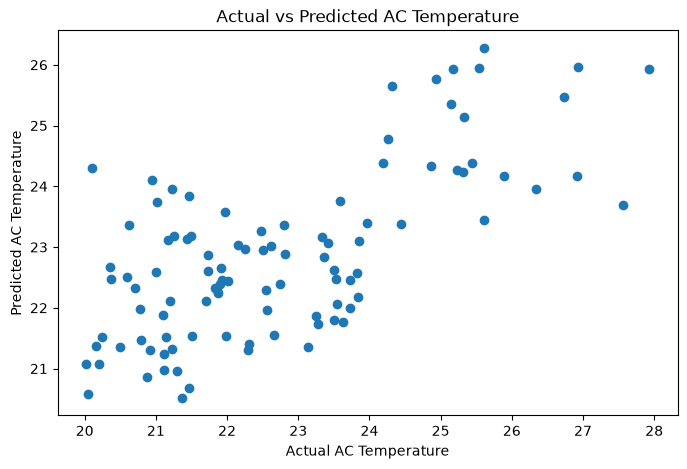

In [15]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual AC Temperature")
plt.ylabel("Predicted AC Temperature")

plt.title("Actual vs Predicted AC Temperature")

plt.show()

Display regression coefficients

In [16]:
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})

print(coefficients)

print("Intercept:", model.intercept_)

               Feature  Coefficient
0         Num_Students    -0.016755
1         Outdoor_Temp    -0.048913
2             Humidity    -0.020525
3            Lights_On    -0.100177
4         Windows_Open    -0.032506
5            Fan_Speed    -0.812919
6  Time_of_Day_Evening    -0.105998
7  Time_of_Day_Morning     0.116484
Intercept: 29.4532365851279
